# Run 4: GloVe-25
Standard `[0,1,1,1]` vs `[0,w,1,1]`, w ∈ {2, 4, 8}, on GloVe-25 angular (first 1M base vectors, 10k queries, cosine searched as inner product on unit vectors, 10 seeds, same M/ef grid as Deep1M and GIST1M).
Distances in the tables are squared L2 between unit vectors, 2 − 2 cos, converted from the raw cosine similarities, so `entry_dist` is the chord distance (cos = 1 − d²/2); see `data/run_4/README.txt`.
Loading, checks and every aggregation live in `scripts/run3_data.py`; plot helpers in `scripts/run3_plots.py`.

**How every number is made** (one named function per step):

```
per query ──(1) run_means / runs──▶ per run ──(2) paired (equal ef0) ─────▶ per seed ──(3) across_seeds──▶ reported
                                             └─(2) matched (matched recall)┘          mean, 95% t interval,
                                                 w minus standard, same seed           seed range, sign test
```

- **(1) query → run**: mean over the run's queries (`runs`; `dist_*` = distance computations per query, `latency_ms` = MQL).
- **(2) run → seed-paired**: w against standard on the same graph seed, at equal ef0 (`paired`) or at the w point's recall
  on the seed's standard curve (`matched`, interpolated in log(1 − recall), no extrapolation).
- **(3) seeds → value**: mean across seeds (n = 10) with a 95% t interval. Every band in the figures is this interval.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.insert(0, "scripts")
import run3_data as rd
import run3_plots as rp

%config InlineBackend.figure_format = "png"
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200, "display.max_colwidth", 100)
rp.setup()

DATA = Path("data/run_4")
DATASETS = ["GloVe-25"]  # rd.DATASETS and rd.GT_DATASETS are run_3's plot lists
DS = DATASETS[0]
data = rd.load(DATA)
runs, queries = data.runs, data.queries
paired = rd.paired(runs)
matched = rd.matched(runs)  # rd.MATCH_METHOD = "log1m"
EFS = {ds: sorted(runs.loc[runs.dataset == ds, "ef0"].unique()) for ds in DATASETS}
print(f"{len(runs)} runs, {len(queries):,} per-query rows ({queries.memory_usage(deep=True).sum() / 1e6:.0f} MB), "
      f"matched recall interpolated with {matched.attrs['method']!r}")

320 runs, 2,400,000 per-query rows (139 MB), matched recall interpolated with 'log1m'


In [2]:
print(runs)
print(queries)

     run_id   dataset  seed  width  ef0  recall_at_10  one_minus_recall  latency_ms  dist_total  dist_layer0  dist_layer1  dist_upper  n_queries  n_levels     status  ground_truth_available  metric_latency_ms
0      4031  GloVe-25     1      1   10       0.77701           0.22299    0.038577    516.2653     390.0050      55.3815     70.8788      10000         4  duplicate                    True           0.039428
1      4019  GloVe-25     1      1   23       0.89848           0.10152    0.065946    816.1347     689.8744      55.3815     70.8788      10000         4   complete                    True           0.066395
2      4015  GloVe-25     1      1   52       0.96424           0.03576    0.127409   1432.8089    1306.5486      55.3815     70.8788      10000         4   complete                    True           0.128424
3      4025  GloVe-25     1      1   79       0.98180           0.01820    0.182952   1970.1381    1843.8778      55.3815     70.8788      10000         4   complet

In [3]:
display(rd.checks(data))

,result,ok
check,,
"per-query means vs run metrics, worst |diff| level 0 / level 1",0.0e+00 / 0.0e+00,True
"total = sum of levels, worst |diff|",1.8e-12,True
"ep1 and level-1 work across ef0, 40 dataset×seed×width groups: mismatching queries","0 ep1, 0 level-1",True
"ep2 (start of level 1), w vs standard on the same graph: mismatching queries",0,True
distinct level ≥ 2 work values within dataset×seed×ef0,1,True
"same ep1 node, different stored distance (queries; largest relative diff)",0 of 159873; 0.0e+00,True
"query×w rows with a zero ep1 distance (x undefined, dropped from Figure 6)",0,True
query_recall: runs with per-query recall; worst |mean − metric.recall_at_k|,320; 3.3e-16,True
metric.recall_at_k nulls,0 of 320,True


## Figure 1. Recall@10 vs MQL
**Question:** at the same ef0, does a wider level-1 beam buy recall, and what does it cost in latency?
**Reading:** recall at equal ef0 is the same for every w (within 0.0005); MQL grows with w at most ef0, most at low ef0 (w=8: +28% at ef0 = 10, +1% at ef0 = 512).
Lines are seed means, dots are seeds, bands are 95% t intervals of MQL across seeds.
Run_3's count of per-seed points with recall = 1 is omitted: no GloVe-25 run reaches recall = 1 (max 0.99967).

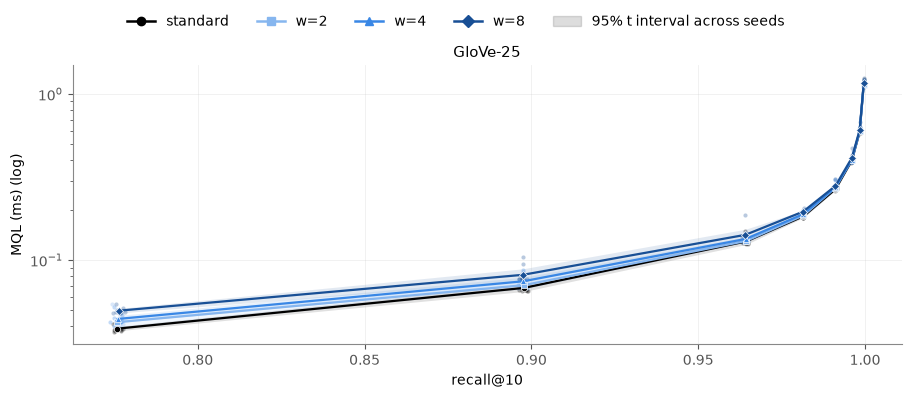

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.9), constrained_layout=True)
ax.set_yscale("log")
x = rp.recall_axis(ax, DS)
rp.curves(ax, runs[runs.dataset == DS], x, "latency_ms")
ax.set_title(DS)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.9))
rp.width_legend(fig)
plt.show()

In [5]:
display(rd.fig1_table(runs).round(4))

recall_at_10                         latency_ms                         latency_ms ±                        
width                   1       2       4       8          1       2       4       8            1       2       4       8
dataset  ef0                                                                                                             
GloVe-25 10        0.7759  0.7759  0.7760  0.7764     0.0386  0.0423  0.0442  0.0496       0.0012  0.0032  0.0022  0.0016
         23        0.8978  0.8978  0.8975  0.8975     0.0680  0.0706  0.0745  0.0815       0.0033  0.0036  0.0044  0.0071
         52        0.9643  0.9643  0.9642  0.9641     0.1294  0.1302  0.1339  0.1418       0.0053  0.0027  0.0040  0.0114
         79        0.9815  0.9815  0.9814  0.9814     0.1835  0.1856  0.1889  0.1954       0.0035  0.0043  0.0037  0.0030
         120       0.9911  0.9911  0.9911  0.9911     0.2672  0.2722  0.2734  0.2790       0.0045  0.0091  0.0082  0.0076
         182       0.9960  0.9960  0.9960  0.9960     0.3986  0.4027  0.4012  0.4113       0.0088  0.0145  0.0079  0.0174
         275       0.9984  0.9984  0.9984  0.9984     0.5887  0.5940  0.5968  0.6053       0.0103  0.0120  0.0116  0.0190
         512       0.9996  0.9996  0.9996  0.9996     1.1446  1.1358  1.1450  1.1568       0.0263  0.0174  0.0258  0.0281

## Figure 2. Total distance computations and MQL vs recall
**Question:** at equal recall, which schedule does less work and answers faster?
**Reading:** the w curves lie on or just above standard at every recall, for both work and MQL, and the gap narrows as recall nears 1.
The table gives the seed-mean work and the time per distance computation, which is why the MQL and work deltas differ.

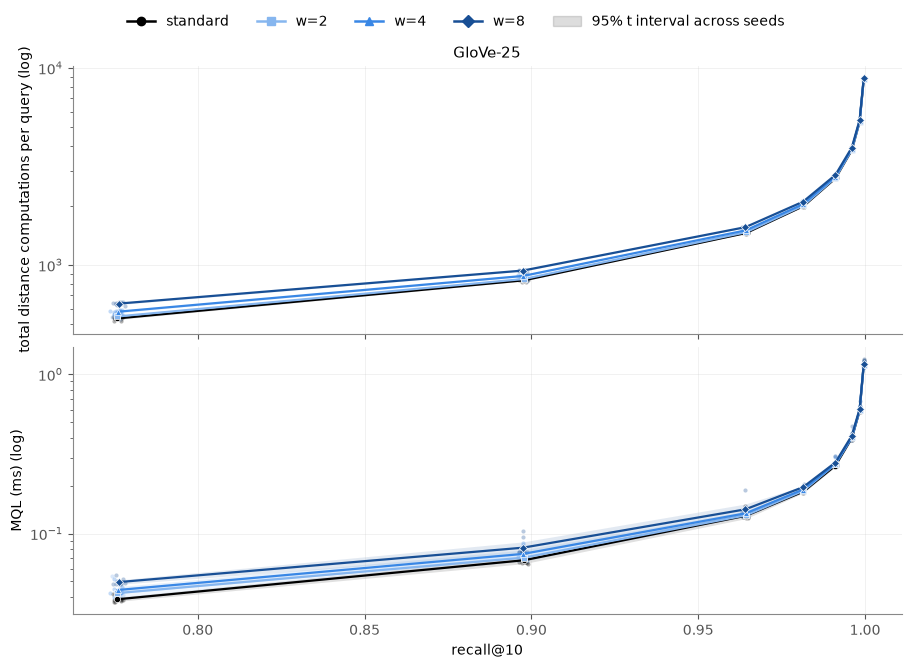

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6.6), constrained_layout=True, sharex="col")
d = runs[runs.dataset == DS]
x = rp.recall_axis(axes[1], DS)
for ax, y in ((axes[0], "dist_total"), (axes[1], "latency_ms")):
    ax.set_yscale("log")
    rp.curves(ax, d, x, y)
axes[0].set(title=DS, xlabel="")  # x is shared down the column
fig.get_layout_engine().set(rect=(0, 0, 1, 0.94))
rp.width_legend(fig)
plt.show()

In [7]:
display(rd.fig2_table(runs).round({**{("dist_total", w): 1 for w in rd.WIDTHS}, **{("ns_per_dist", w): 2 for w in rd.WIDTHS}}))

dist_total                         ns_per_dist                     
width                 1       2       4       8           1      2      4      8
dataset  ef0                                                                    
GloVe-25 10       534.6   547.0   578.2   636.1       72.28  77.26  76.42  77.94
         23       835.1   847.7   878.5   935.5       81.37  83.27  84.76  87.06
         52      1451.7  1465.0  1496.7  1553.6       89.14  88.85  89.50  91.24

## Figure 3. Delta vs standard at matched recall
**Question:** at the recall a w run reaches, how much more or less work and latency does it need than standard on the same seed?
**Reading:** every w needs more at matched recall, growing with w: total work +0.8%, +2.7%, +6.3% and MQL +1.4%, +3.6%, +8.9% for w=2, 4, 8 (table intervals all above 0); the excess shrinks toward 0 as recall nears 1.
Solid is MQL, dashed is total distance computations, in %; standard is interpolated in log(1 − recall); bands are 95% t intervals.
The table averages each seed over its matched ef0 points, then across seeds.

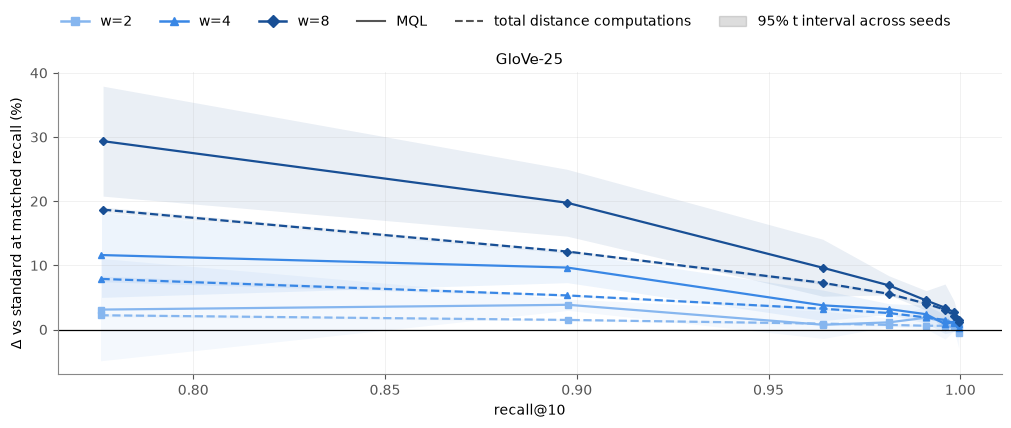

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
x = rp.recall_axis(ax, DS)
rp.delta_vs_standard(ax, matched[matched.dataset == DS], x, ["latency_delta_pct", "dist_total_delta_pct"])
ax.set_title(DS)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.89))
rp.width_legend(fig, rd.WS, extra=[("MQL", "-"), ("total distance computations", "--")])
plt.show()

In [9]:
display(pd.concat({c: rd.matched_summary(matched, c) for c in ["dist_total_delta_pct", "latency_delta_pct"]}, axis=1).round(3))

dist_total_delta_pct                                                          latency_delta_pct                                                          
                               mean  ci_lo  ci_hi seed_min seed_max n_seeds n_below_0 sign_p              mean  ci_lo   ci_hi seed_min seed_max n_seeds n_below_0 sign_p
dataset  width                                                                                                                                                          
GloVe-25 2                    0.809  0.667  0.950    0.340    1.059      10         0  0.002             1.423  0.741   2.105   -0.556    2.677      10         1  0.021
         4                    2.670  2.387  2.953    2.003    3.112      10         0  0.002             3.580  2.812   4.349    2.432    6.311      10         0  0.002
         8                    6.304  5.764  6.844    5.084    7.035      10         0  0.002             8.903  7.277  10.529    5.906   13.163      10         0  0.002

## Figure 4. Cost by layer at equal ef0
**Question:** at the same ef0, does the level-0 work the better entry saves pay for the extra level-1 work?
**Reading:** no. Level-1 extra is flat in ef0 (26, 68, 135 per query for w=2, 4, 8) and about 2 to 9 times the level-0 saving, so the net is negative at every ef0 and w. In absolute terms it deepens from ef0 = 23 on (w=8: −100.3 → −120.2 per query), while as a share of standard total it shrinks (w=8: −19.0% at ef0 = 10 → −1.4% at ef0 = 512).
Absolute values first, then in % of standard total; bands are 95% t intervals.

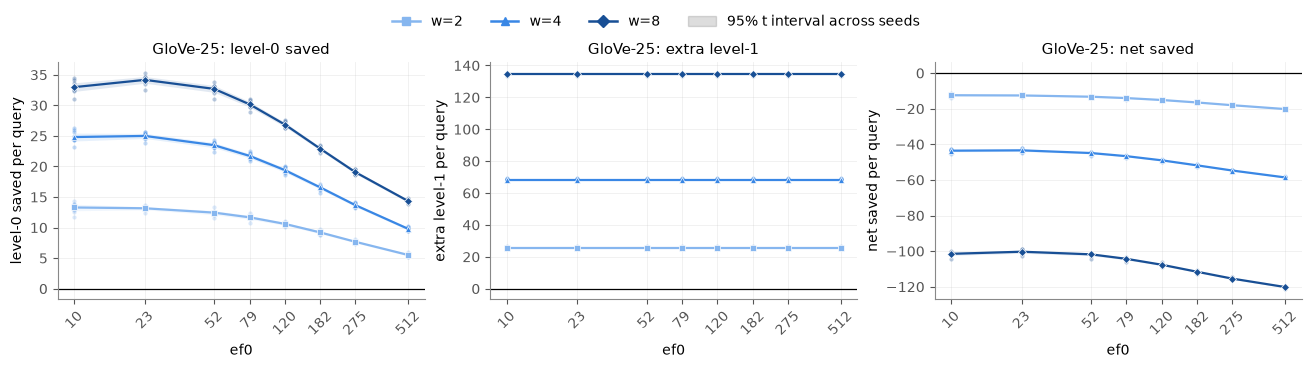

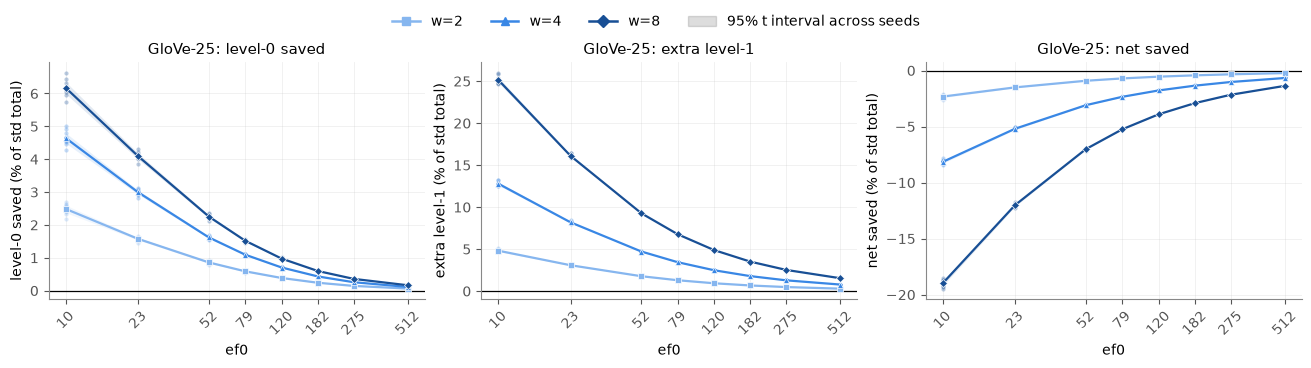

In [10]:
PANELS = [("layer0_saved", "level-0 saved"), ("layer1_extra", "extra level-1"), ("net_saved", "net saved")]
for suffix in ("", "_pct"):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True, sharex="row")
    for j, (col, title) in enumerate(PANELS):
        ax = axes[j]
        rp.ef_axis(ax, EFS[DS])
        rp.curves(ax, paired[paired.dataset == DS], "ef0", col + suffix)
        ax.axhline(0, color="#000000", lw=0.9)
        ax.set_title(f"{DS}: {title}")
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.9))
    rp.width_legend(fig, rd.WS)
    plt.show()

In [11]:
fig4 = rd.fig4_table(paired)
r4 = {c: (5 if c == "recall_gain" else 3 if "pct" in c or c == "net_sign_p" else 2) for c in fig4.columns}
print(f"Net balance, {DS}:")
display(fig4.round(r4))

Net balance, GloVe-25:


layer0_saved  layer1_extra  net_saved  net_ci_lo  net_ci_hi  net_min  net_max  net_pct  net_pct_ci_lo  net_pct_ci_hi  net_pct_min  net_pct_max  seeds_net_pos  seeds  net_sign_p  recall_gain
dataset  ef0 width                                                                                                                                                                                               
GloVe-25 10  2             13.29         25.73     -12.45     -12.97     -11.93   -14.01   -11.41   -2.329         -2.427         -2.230       -2.587       -2.094              0     10       0.002      0.00007
             4             24.81         68.40     -43.59     -44.18     -43.00   -45.60   -42.66   -8.156         -8.281         -8.030       -8.421       -7.828              0     10       0.002      0.00013
             8             32.98        134.51    -101.53    -102.36    -100.69  -104.24   -99.86  -18.995        -19.214        -18.776      -19.465      -18.489              0     10       0.002      0.00057
         23  2             13.16         25.73     -12.58     -12.86     -12.29   -13.45   -12.16   -1.506         -1.545         -1.467       -1.598       -1.438              0     10       0.002     -0.00005
             4             25.00         68.40     -43.41     -44.01     -42.81   -44.92   -42.14   -5.198         -5.280         -5.117       -5.335       -5.007              0     10       0.002     -0.00028
             8             34.17        134.51    -100.34    -101.18     -99.50  -102.78   -98.77  -12.015        -12.122        -11.908      -12.229      -11.759              0     10       0.002     -0.00034
         52  2             12.45         25.73     -13.29     -13.55     -13.03   -14.21   -13.05   -0.915         -0.933         -0.898       -0.975       -0.894              0     10       0.002     -0.00003
             4             23.48         68.40     -44.92     -45.39     -44.45   -46.36   -44.18   -3.094         -3.127         -3.062       -3.179       -3.022              0     10       0.002     -0.00013
             8             32.69        134.51    -101.81    -102.51    -101.11  -104.18  -100.80   -7.013         -7.057         -6.970       -7.143       -6.909              0     10       0.002     -0.00022
         79  2             11.68         25.73     -14.06     -14.33     -13.78   -14.98   -13.62   -0.707         -0.721         -0.693       -0.751       -0.686              0     10       0.002     -0.00001
             4             21.73         68.40     -46.68     -47.09     -46.27   -47.89   -45.75   -2.348         -2.369         -2.328       -2.401       -2.304              0     10       0.002     -0.00010
             8             30.17        134.51    -104.34    -104.93    -103.75  -106.28  -103.42   -5.249         -5.276         -5.222       -5.328       -5.216              0     10       0.002     -0.00013
         120 2             10.60         25.73     -15.14     -15.33     -14.95   -15.58   -14.71   -0.550         -0.557         -0.543       -0.565       -0.532              0     10       0.002     -0.00001
             4             19.39         68.40     -49.02     -49.36     -48.68   -49.82   -48.27   -1.781         -1.793         -1.769       -1.805       -1.755              0     10       0.002     -0.00002
             8             26.84        134.51    -107.67    -108.18    -107.15  -108.91  -106.38   -3.911         -3.926         -3.897       -3.945       -3.887              0     10       0.002     -0.00003
         182 2              9.20         25.73     -16.53     -16.70     -16.37   -16.85   -16.14   -0.432         -0.436         -0.427       -0.439       -0.420              0     10       0.002     -0.00002
             4             16.56         68.40     -51.84     -52.19     -51.50   -52.56   -50.95   -1.354         -1.363         -1.345       -1.370       -1.331              0     10       0.002     -0.00002
             8             22.

## Figure 5. Distance from the query to `ep1`
**Question:** does the wider level-1 beam hand level 0 a closer entry point?
**Reading:** yes, by 4–9% at the median (0.634 standard vs 0.606, 0.587, 0.576 for w=2, 4, 8), and only for the 29%, 50% and 61% of queries whose `ep1` changes; it never gets farther.
Seeds pooled; one panel because `ep1` does not depend on ef0 (checked). Violins are cut at p0.5–p99.5;
the share of queries with `ep1` unchanged is printed above each. The distance is the chord between unit vectors.

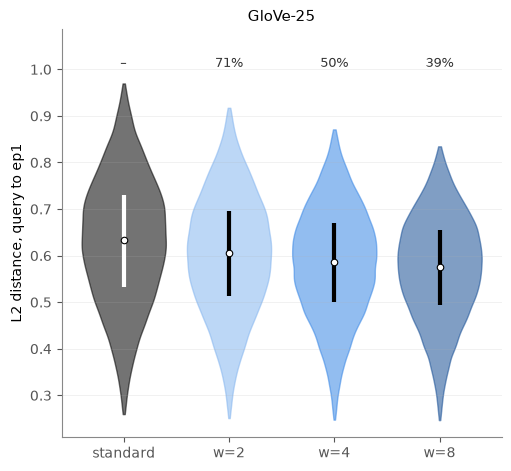

In [12]:
entries = rd.entry_distances(queries)
fig, ax = plt.subplots(figsize=(5, 4.6), constrained_layout=True)
rp.entry_violins(ax, entries[entries.dataset == DS], log=DS in rd.CLUSTERED)
ax.set_title(DS)
plt.show()

In [13]:
display(rd.entry_table(entries).round(3))

median     q1     q3  unchanged_id  closer  farther  unchanged_ci_lo  unchanged_ci_hi
dataset  width                                                                                       
GloVe-25 1       0.634  0.533  0.731         1.000   0.000      0.0            1.000            1.000
         2       0.606  0.513  0.696         0.712   0.288      0.0            0.710            0.715
         4       0.587  0.500  0.670         0.499   0.501      0.0            0.495            0.502
         8       0.576  0.494  0.655         0.388   0.612      0.0            0.385            0.391

## Figure 6. Level-0 sensitivity to the entry point
**Question:** how much level-0 work does a closer `ep1` save, per query?
**Reading:** about 7.4% per 10% closer at ef0 = 10, falling to 0.13% at ef0 = 512.
Queries pooled across seeds and widths, one panel per ef0, x on a log-ratio axis with % labels.
The elasticity is fitted per seed (all queries) and reported as the seed mean with a 95% t interval;
the appendix repeats it without the unchanged-`ep1` queries.

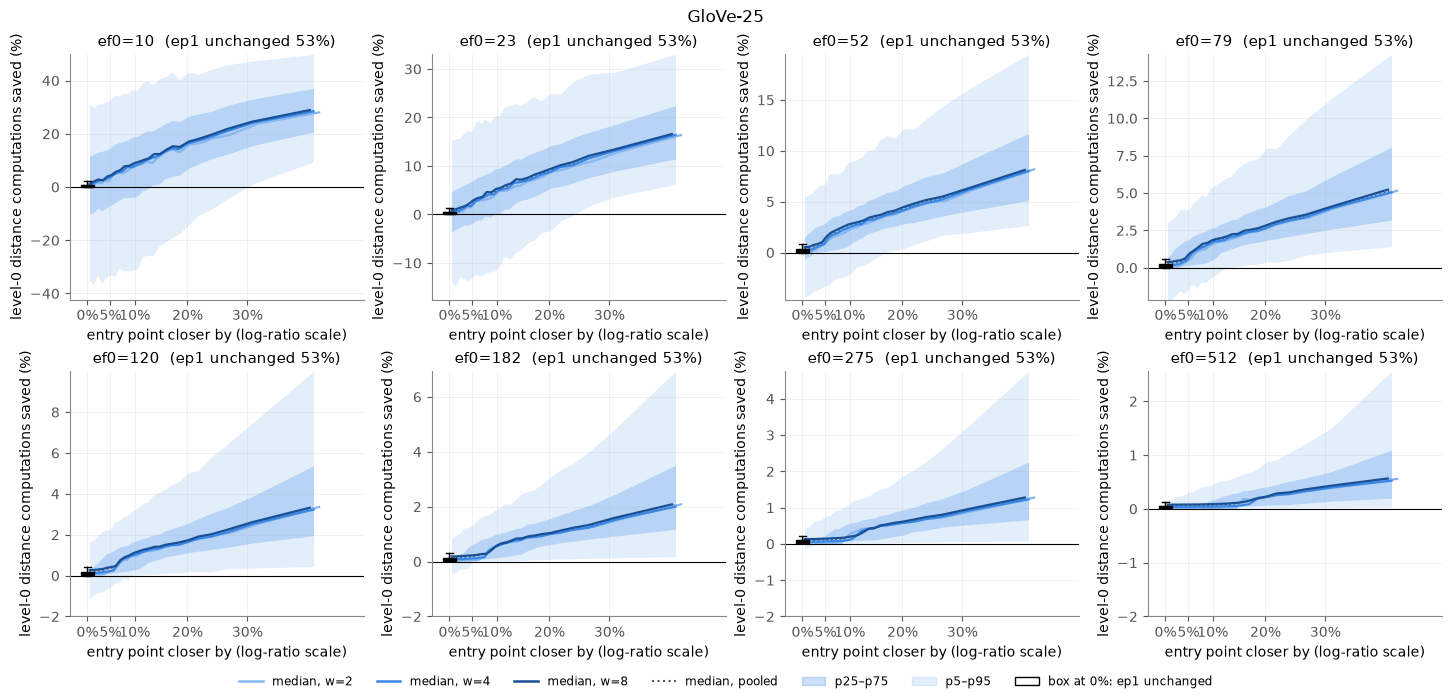

In [14]:
for ds in DATASETS:
    ncols = 5 if ds in rd.CLUSTERED else 4
    nrows = -(-len(EFS[ds]) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows + 0.5), constrained_layout=True, squeeze=False)
    for ax, ef in zip(axes.flat, EFS[ds]):
        rp.sensitivity_fan(ax, rd.fig6_pairs(queries, ds, ef))
    for ax in axes.flat[len(EFS[ds]):]:
        ax.axis("off")
    fig.suptitle(ds)
    rp.sensitivity_legend(fig)
    plt.show()

In [15]:
print("Elasticity, widths pooled, as % level-0 saving per 10% closer entry point (seed mean, 95% t interval, seed range):")
display(rd.elasticity(queries).round(3))
print("Level-0 saving (%), queries with unchanged ep1 vs closer ep1, and the share of the mean saving from unchanged-ep1 queries:")
display(rd.zero_table(queries).round(3))

Elasticity, widths pooled, as % level-0 saving per 10% closer entry point (seed mean, 95% t interval, seed range):


elasticity  pct_per_10pct  ci_lo  ci_hi  seed_min  seed_max  share_near  near_pct_per_10pct  near_min  near_max  queries_per_seed
dataset  ef0                                                                                                                                   
GloVe-25 10        0.726          7.367  7.232  7.501     7.154     7.789       0.968               8.188     7.974     8.408           30000.0
         23        0.403          4.155  4.098  4.213     4.068     4.297       0.968               4.644     4.552     4.699           30000.0
         52        0.194          2.020  1.977  2.063     1.915     2.143       0.968               2.271     2.228     2.314           30000.0
         79        0.126          1.317  1.288  1.347     1.256     1.408       0.968               1.462     1.416     1.500           30000.0
         120       0.080          0.835  0.813  0.856     0.785     0.890       0.968               0.904     0.884     0.921           30000.0
         182       0.049          0.512  0.498  0.527     0.483     0.548       0.968               0.533     0.520     0.546           30000.0
         275       0.029          0.307  0.296  0.317     0.287     0.333       0.968               0.303     0.293     0.311           30000.0
         512       0.013          0.133  0.127  0.139     0.121     0.146       0.968               0.119     0.114     0.125           30000.0

Level-0 saving (%), queries with unchanged ep1 vs closer ep1, and the share of the mean saving from unchanged-ep1 queries:


share_x0  y_mean_x0  y_median_x0  y_mean_xpos  y_median_xpos  y_mean_all  y_median_all  saving_share_unchanged
dataset  ef0                                                                                                                
GloVe-25 10      0.533      0.516        0.323        9.624         11.051       4.770         0.586                   0.058
         23      0.533      0.404        0.220        6.345          6.049       3.179         0.498                   0.068
         52      0.533      0.253        0.140        3.430          2.901       1.737         0.355                   0.077
         79      0.533      0.186        0.111        2.291          1.880       1.170         0.270                   0.085
         120     0.533      0.135        0.084        1.449          1.145       0.749         0.193                   0.096
         182     0.533      0.097        0.062        0.869          0.630       0.458         0.131                   0.113
         275     0.533      0.070        0.045        0.504          0.244       0.273         0.088                   0.136
         512     0.533      0.043        0.027        0.212          0.081       0.122         0.047                   0.187

## Appendix: sensitivity
A. Matched-recall interpolation: log(1 − recall) (default) vs linear in recall, the held-out check behind the choice,
and the points dropped for lying outside the standard range.
C. MQL delta without the ef0 = 10 points. D. Bands: seed min–max (original) vs 95% t interval.
E. Figure 6 elasticity without the queries whose `ep1` did not change.

In [16]:
linear = rd.matched(runs, "linear")
print("A1. Matched-recall summary, total distance computations and MQL (%), log1m vs linear:")
cols = ["mean", "ci_lo", "ci_hi", "seed_min", "seed_max", "n_below_0", "sign_p"]
display(pd.concat({(c, m.attrs["method"]): rd.matched_summary(m, c)[cols]
                   for c in ["dist_total_delta_pct", "latency_delta_pct"] for m in (matched, linear)}, axis=1).round(3))
print("A2. Seed mean by ef0 (%), total distance computations, log1m vs linear:")
display(pd.concat({m.attrs["method"]: rd.matched_by_ef(m, "dist_total_delta_pct")["mean"].unstack("width")
                   for m in (matched, linear)}, axis=1).round(2))
print("A3. Held-out standard point, interpolation error (% of measured, > 0 = standard overstated):")
display(rd.heldout_interp_error(runs).round(2))
print("A4. Seeds dropped (w recall outside the seed's standard range), log1m and linear:")
display(pd.concat({m.attrs["method"]: rd.dropped_points(m) for m in (matched, linear)}, axis=1).fillna(0).astype(int))

A1. Matched-recall summary, total distance computations and MQL (%), log1m vs linear:


dist_total_delta_pct                                                                                                          latency_delta_pct                                                           \
                              log1m                                                  linear                                                              log1m                                                   linear   
                               mean  ci_lo  ci_hi seed_min seed_max n_below_0 sign_p   mean  ci_lo  ci_hi seed_min seed_max n_below_0 sign_p              mean  ci_lo   ci_hi seed_min seed_max n_below_0 sign_p   mean   
dataset  width                                                                                                                                                                                                            
GloVe-25 2                    0.809  0.667  0.950    0.340    1.059         0  0.002  0.720  0.565  0.875    0.176    0.985         0  0.002             1.423  0.741   2.105   -0.556    2.677         1  0.021  1.314   
         4                    2.670  2.387  2.953    2.003    3.112         0  0.002  2.563  2.278  2.848    1.887    2.989         0  0.002             3.580  2.812   4.349    2.432    6.311         0  0.002  3.447   
         8                    6.304  5.764  6.844    5.084    7.035         0  0.002  6.178  5.632  6.724    4.983    6.950         0  0.002             8.903  7.277  10.529    5.906   13.163         0  0.002  8.746   

                                                                  
                                                                  
                ci_lo   ci_hi seed_min seed_max n_below_0 sign_p  
dataset  width                                                    
GloVe-25 2      0.611   2.017   -0.761    2.618         1  0.021  
         4      2.665   4.229    2.280    6.227         0  0.002  
         8      7.097  10.395    5.782   13.066         0  0.002

A2. Seed mean by ef0 (%), total distance computations, log1m vs linear:


log1m              linear             
width            2     4      8      2     4      8
dataset  ef0                                       
GloVe-25 10   2.22  7.88  18.68   2.14  7.77  18.52
         23   1.49  5.32  12.16   1.40  5.23  12.04
         52   0.92  3.23   7.27   0.83  3.13   7.14
         79   0.72  2.57   5.56   0.65  2.49   5.45
         120  0.59  1.87   4.03   0.54  1.82   3.96
         182  0.58  1.50   3.09   0.46  1.37   2.96
         275  0.32  0.95   2.15   0.19  0.75   1.95
         512  0.37  0.81   1.52   0.29  0.73   1.43

A3. Held-out standard point, interpolation error (% of measured, > 0 = standard overstated):


linear  log1m
dataset  ef0               
GloVe-25 23    35.07  10.93
         52    20.62   6.39
         79    15.04   4.00
         120   16.46   4.06
         182   17.49   3.95
         275   32.28   7.67

A4. Seeds dropped (w recall outside the seed's standard range), log1m and linear:


log1m       linear      
width            2  4  8      2  4  8
dataset  ef0                         
GloVe-25 10      5  5  3      5  5  3

B. Omitted: it cuts the clustered sets' standard curve at ef0 ≤ 52, and GloVe-25 is not a clustered set.

In [17]:
print("C. MQL delta at matched recall (%) without the ef0 = 10 points, log1m and linear:")
display(pd.concat({m.attrs["method"]: rd.matched_summary(m[m.ef0 > 10], "latency_delta_pct")[["mean", "ci_lo", "ci_hi", "seed_min", "seed_max", "n_below_0"]]
                   for m in (matched, linear)}, axis=1).round(3))
print("C. MQL delta, seed mean by ef0 (%), log1m:")
display(rd.matched_by_ef(matched, "latency_delta_pct")["mean"].unstack("width").round(2))

C. MQL delta at matched recall (%) without the ef0 = 10 points, log1m and linear:


log1m                                           linear                                          
                 mean  ci_lo  ci_hi seed_min seed_max n_below_0   mean  ci_lo  ci_hi seed_min seed_max n_below_0
dataset  width                                                                                                  
GloVe-25 2      1.296  0.628  1.963   -0.556    2.677         1  1.188  0.500  1.875   -0.761    2.618         1
         4      3.039  2.493  3.585    2.184    4.682         0  2.908  2.366  3.450    2.107    4.590         0
         8      6.876  5.148  8.604    4.819   13.163         0  6.727  4.991  8.463    4.663   13.066         0

C. MQL delta, seed mean by ef0 (%), log1m:


width            2      4      8
dataset  ef0                    
GloVe-25 10   3.11  11.61  29.36
         23   3.85   9.66  19.76
         52   0.74   3.77   9.63
         79   1.12   3.17   6.88
         120  1.85   2.38   4.53
         182  1.19   0.85   3.39
         275  0.84   1.22   2.71
         512 -0.52   0.22   1.23

In [18]:
print("D. Total distance computations at matched recall (log1m), per ef0: seed min–max vs 95% t interval (%):")
b = rd.matched_by_ef(matched, "dist_total_delta_pct", ["mean", "seed_min", "seed_max", "ci_lo", "ci_hi", "n_seeds"])
display(b.round(2))
print("E. Figure 6 elasticity without the queries whose ep1 did not change (x = 0):")
display(rd.elasticity(queries, exclude_unchanged=True).round(3))
import resource
print(f"peak RSS {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.2f} GB")

D. Total distance computations at matched recall (log1m), per ef0: seed min–max vs 95% t interval (%):


mean  seed_min  seed_max  ci_lo  ci_hi  n_seeds
dataset  ef0 width                                                  
GloVe-25 10  2       2.22      1.97      2.41   2.00   2.44        5
             4       7.88      7.55      8.31   7.45   8.32        5
             8      18.68     18.14     19.21  18.28  19.08        7
         23  2       1.49      1.10      1.75   1.33   1.66       10
             4       5.32      5.06      5.69   5.16   5.47       10
             8      12.16     11.65     12.63  11.91  12.40       10
         52  2       0.92      0.59      1.22   0.75   1.09       10
             4       3.23      2.81      3.70   3.04   3.43       10
             8       7.27      6.75      7.94   7.02   7.52       10
         79  2       0.72     -0.02      1.05   0.50   0.93       10
             4       2.57      2.05      2.86   2.41   2.73       10
             8       5.56      4.95      5.89   5.34   5.78       10
         120 2       0.59      0.25      0.77   0.47   0.71       10
             4       1.87      1.61      2.25   1.74   2.01       10
             8       4.03      3.45      4.44   3.85   4.21       10
         182 2       0.58      0.03      0.95   0.35   0.80       10
             4       1.50      1.01      1.95   1.25   1.74       10
             8       3.09      2.31      3.52   2.82   3.36       10
         275 2       0.32     -0.19      0.55   0.13   0.52       10
             4       0.95      0.23      1.41   0.67   1.23       10
             8       2.15      1.36      2.76   1.83   2.47       10
         512 2       0.37      0.23      1.65   0.05   0.69       10
             4       0.81      0.66      2.09   0.49   1.13       10
             8       1.52      1.37      2.80   1.19   1.84       10

E. Figure 6 elasticity without the queries whose ep1 did not change (x = 0):


elasticity  pct_per_10pct  ci_lo  ci_hi  seed_min  seed_max  share_near  near_pct_per_10pct  near_min  near_max  queries_per_seed
dataset  ef0                                                                                                                                   
GloVe-25 10        0.677          6.880  6.720  7.040     6.660     7.399       0.968               8.029     7.817     8.261           14012.7
         23        0.371          3.829  3.747  3.912     3.658     3.984       0.968               4.475     4.204     4.683           14012.7
         52        0.174          1.814  1.760  1.868     1.661     1.949       0.968               2.107     2.016     2.188           14012.7
         79        0.113          1.184  1.141  1.228     1.085     1.310       0.968               1.342     1.262     1.407           14012.7
         120       0.073          0.767  0.737  0.797     0.692     0.843       0.968               0.840     0.795     0.868           14012.7
         182       0.047          0.491  0.470  0.512     0.449     0.536       0.968               0.514     0.494     0.528           14012.7
         275       0.029          0.309  0.294  0.324     0.282     0.344       0.968               0.307     0.289     0.316           14012.7
         512       0.014          0.144  0.136  0.152     0.128     0.160       0.968               0.129     0.121     0.138           14012.7

peak RSS 0.77 GB


## Figures 7–8. Entry gain vs cost at matched recall
**Question:** for queries whose entry point improves by a given amount, does the level-0 work saved at the *same recall* pay for the extra level-1 work?

**How:** each query keeps one entry gain at every ef0 (ep1 does not depend on ef0), so queries are grouped once per w:
`unchanged` (same ep1) and three equal-size groups of "closer by" among the rest (`rd.entry_gain_groups`).
Per group and seed, the queries' mean recall and cost over the ef0 grid give one recall–cost curve for w and one for standard on the same queries (`rd.group_curves`).
The two curves are compared at recall targets R, interpolated in log(1 − recall) (`rd.group_matched`):
level-0 saved = L0_std(R) − L0_w(R); extra level-1 = L1_w − L1_std (no ef0 dependence); net = the difference.

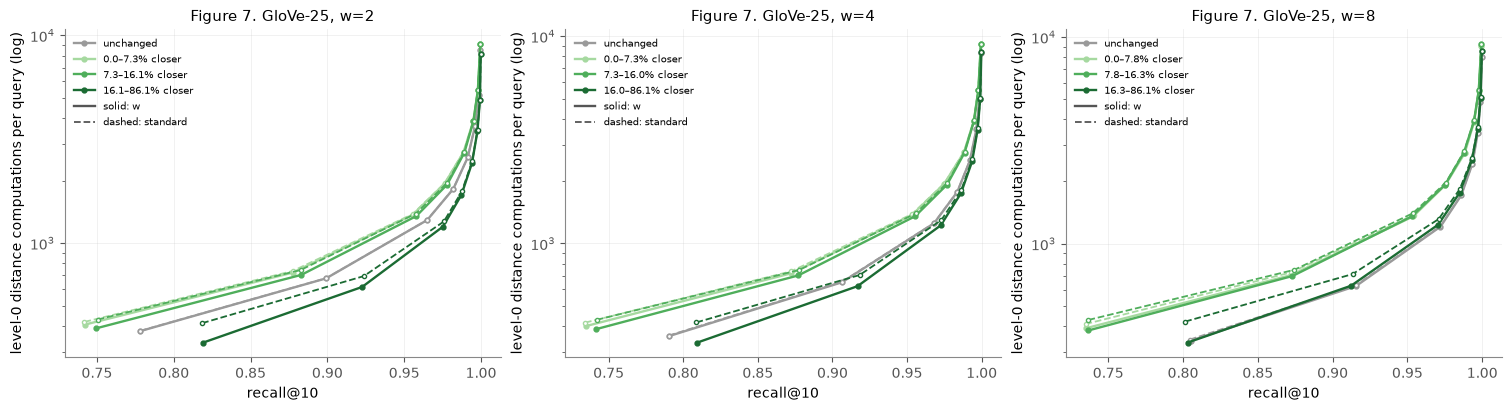

In [19]:
qg = rd.entry_gain_groups(queries)
groups = qg.attrs["group_names"]
gcurves = rd.group_curves(qg)
gmatched = rd.group_matched(gcurves)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True, squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, w in enumerate(rd.WS):
        ax = axes[i, j]
        ax.set_yscale("log")
        x = rp.recall_axis(ax, ds)
        rp.group_recall_cost(ax, gcurves[(gcurves.dataset == ds) & (gcurves.width == w)], groups[(ds, w)], x=x)
        ax.set_title(f"Figure 7. {ds}, w={w}")
        ax.legend(fontsize=7.5, loc="upper left")
plt.show()

**Entry-gain distribution.** How many queries get an entry point that is x% closer under w, before grouping them.
Each line is the share of queries at least x% closer (seeds pooled, log x); it starts at the share whose ep1 changed, the rest are unchanged.
Ticks are the group edges used in Figures 7–8, so each group between ticks holds a third of the changed queries.

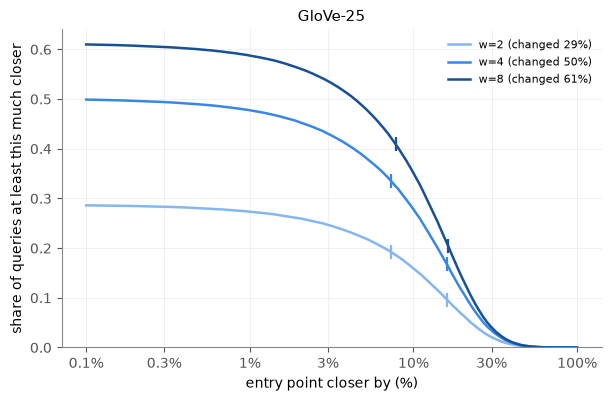

queries  unchanged  at_least_5pct  at_least_10pct  at_least_30pct  changed_p25  changed_p50  changed_p75  changed_p90
dataset  width                                                                                                                       
GloVe-25 2       100000      0.712          0.221           0.159           0.021        5.399       11.369       19.039       27.264
         4       100000      0.499          0.385           0.278           0.034        5.381       11.364       18.859       26.759
         8       100000      0.388          0.483           0.351           0.040        5.902       11.777       19.028       26.723

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.9), constrained_layout=True)
edges = {w: [float(n.split("–")[0]) for n in groups[(DS, w)][2:]] for w in rd.WS}
rp.entry_gain_survival(ax, queries[queries.dataset == DS], edges)
ax.set_title(DS)
ax.legend(fontsize=8)
plt.show()
display(rd.entry_gain_distribution(queries).round(3))

**Figure 7** shows the per-group recall–cost curves (seed means; solid w, dashed standard on the same queries). The horizontal gap between a pair is what the entry gain is worth at that recall.
**Figure 8** reads them at fixed recall targets: purple lines are the level-0 saving, one per target; the black dashed line is the extra level-1 work of the same queries. Where purple is above black, the wide search pays. Error bars are 95% t intervals across seeds.

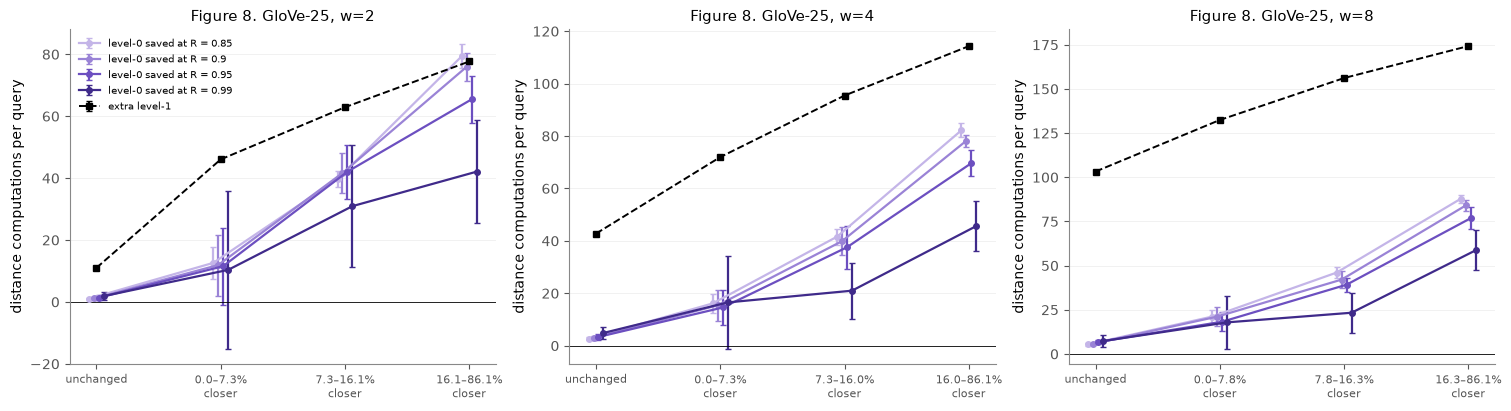

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True, squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, w in enumerate(rd.WS):
        ax = axes[i, j]
        rp.group_balance(ax, gmatched[(gmatched.dataset == ds) & (gmatched.width == w)], groups[(ds, w)])
        ax.set_title(f"Figure 8. {ds}, w={w}")
        if j == 0:
            ax.legend(fontsize=7.5, loc="upper left")
plt.show()

In [22]:
print("Balance at matched recall per entry-gain group (seed mean, distance computations per query; net with its 95% t interval):")
bal = rd.across_seeds(gmatched, ["layer0_saved", "layer1_extra", "net_saved", "payback"], ["dataset", "width", "gain_group", "recall_target"])
tab = bal.xs("mean", axis=1, level=1).join(bal["net_saved"][["ci_lo", "ci_hi", "n_below_0"]].add_prefix("net_"))
per_group = gcurves.groupby(["dataset", "width", "gain_group"], observed=True).agg(queries_per_seed=("n_queries", "mean"), entry_gain_pct=("entry_gain_pct", "mean"))
display(tab.join(per_group, on=["dataset", "width", "gain_group"]).round(2))

Balance at matched recall per entry-gain group (seed mean, distance computations per query; net with its 95% t interval):


layer0_saved  layer1_extra  net_saved  payback  net_ci_lo  net_ci_hi  net_n_below_0  queries_per_seed  entry_gain_pct
dataset  width gain_group recall_target                                                                                                                       
GloVe-25 2     0          0.85                   1.06         11.01      -9.95     0.10     -10.16      -9.74             10            7124.1        0.000000
                          0.90                   1.11         11.01      -9.90     0.10     -10.31      -9.49             10            7124.1        0.000000
                          0.95                   1.36         11.01      -9.65     0.12     -10.37      -8.94             10            7124.1        0.000000
                          0.99                   1.88         11.01      -9.13     0.17     -10.32      -7.94             10            7124.1        0.000000
               1          0.85                  12.61         46.05     -33.43     0.27     -38.75     -28.12             10             958.6        3.570000
                          0.90                  11.92         46.05     -34.13     0.26     -44.06     -24.20             10             958.6        3.570000
                          0.95                  11.55         46.05     -34.49     0.25     -47.02     -21.97             10             958.6        3.570000
                          0.99                  10.35         46.05     -35.70     0.23     -61.35     -10.04              8             958.6        3.570000
               2          0.85                  39.69         62.90     -23.21     0.63     -25.76     -20.66             10             958.6       11.470000
                          0.90                  41.64         62.90     -21.26     0.66     -27.37     -15.16             10             958.6       11.470000
                          0.95                  42.08         62.90     -20.81     0.67     -29.21     -12.42             10             958.6       11.470000
                          0.99                  30.94         62.90     -31.96     0.49     -51.84     -12.08              9             958.6       11.470000
               3          0.85                  79.39         77.68       1.71     1.02      -1.82       5.24              3             958.7       25.190001
                          0.90                  75.99         77.68      -1.69     0.98      -6.00       2.61              7             958.7       25.190001
                          0.95                  65.46         77.68     -12.22     0.84     -19.56      -4.87              9             958.7       25.190001
                          0.99                  42.08         77.68     -35.60     0.54     -52.09     -19.10             10             958.7       25.190001
         4     0          0.85                   2.68         42.77     -40.08     0.06     -40.88     -39.29             10            4986.4        0.000000
                          0.90                   2.94         42.77     -39.82     0.07     -40.61     -39.04             10            4986.4        0.000000
                          0.95                   3.34         42.77     -39.42     0.08     -40.63     -38.21             10            4986.4        0.000000
                          0.99                   4.86         42.77     -37.91     0.11     -40.20     -35.61             10            4986.4        0.000000
               1          0.85                  16.14         71.97     -55.83     0.22     -59.55     -52.11             10            1671.2        3.590000
                          0.90                  15.42         71.97     -56.55     0.21     -62.45     -50.64             10            1671.2        3.590000
                          0.95                  14.57         71.97     -57.40     0.20     -63.71     -51.09             10            1671.2        3.590000
                          0.99                  16.51         71.9

## Figure 9. Tail of the per-query work at matched recall
**Question:** do the costliest queries gain or lose more than the average query? MQL is per batch, so a p95 latency is not available; per-query distance computations are.
**How:** per run, p95 over queries of total distance computations (all levels), then matched exactly as in Figure 3: the standard p95 curve is read at the w point's *mean* recall (log(1 − recall), same seed), Δ = 100 (p95_w / p95_std − 1).
Mean recall fixes the operating point but says nothing about the queries in the tail, so the table also gives the recall of each run's costliest 5% of queries, w minus standard at the same mean recall.
**Reading:** p95 moves with the mean and pays slightly less than it (w=8: +5.6% vs +6.3%; w=2: +0.7% vs +0.8%), and the costliest 5% of queries keep their recall (within 0.11 recall points of standard, intervals span 0). The ef0 = 10 points rest on 5, 5 and 7 seeds for w=2, 4, 8: the other 13 w runs lie outside their seed's standard recall range and are not matched.

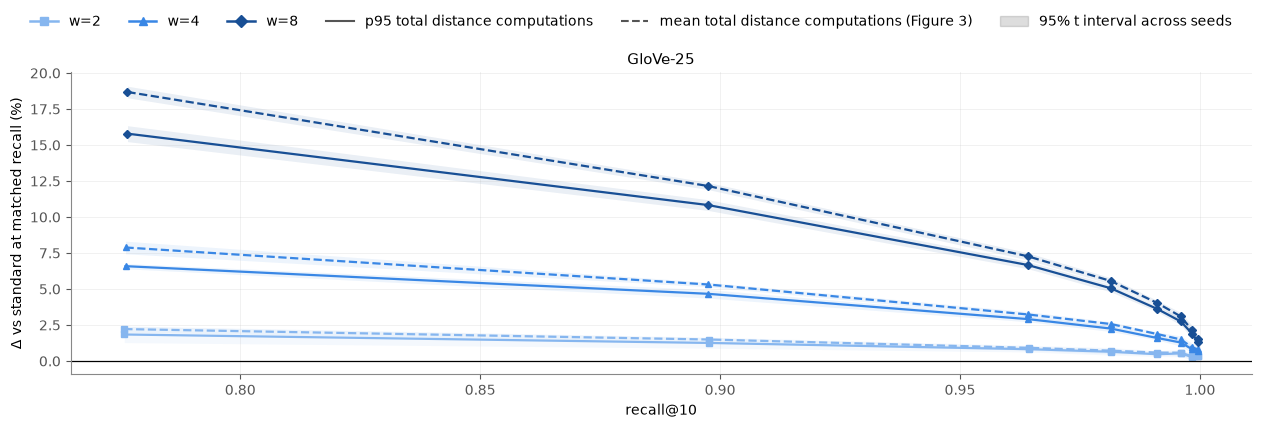

In [23]:
runs_t = rd.query_tails(DATA, runs)
tails = rd.tail_matched(runs_t)
P95 = f"dist_total_p{rd.TAIL_Q}"

fig, ax = plt.subplots(figsize=(12.5, 4.2), constrained_layout=True)
x = rp.recall_axis(ax, DS)
rp.delta_vs_standard(ax, tails[tails.dataset == DS], x, [P95 + "_delta_pct", "dist_total_delta_pct"])
ax.set_title(DS)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.89))
rp.width_legend(fig, rd.WS, extra=[(f"p{rd.TAIL_Q} total distance computations", "-"), ("mean total distance computations (Figure 3)", "--")])
plt.show()

In [24]:
print(f"Matched recall, seed mean over ef0 then across seeds: Δ mean and Δ p{rd.TAIL_Q} total distance computations (%), "
      f"and Δ recall@10 of the costliest {100 - rd.TAIL_Q}% of queries (recall points, > 0 = w better):")
cols = ["mean", "ci_lo", "ci_hi", "n_below_0", "n_seeds"]
tail_tab = pd.concat({c: rd.matched_summary(tails, c)[cols]
                      for c in ["dist_total_delta_pct", P95 + "_delta_pct", "tail_recall_delta"]}, axis=1)
tail_tab[[("tail_recall_delta", c) for c in ["mean", "ci_lo", "ci_hi"]]] *= 100
display(tail_tab.round(3))
print("Per ef0, seed mean: absolute p95 and tail recall, standard and w:")
display(rd.across_seeds(runs_t, [P95, "tail_recall"], ["dataset", "ef0", "width"]).xs("mean", axis=1, level=1).unstack("width").round(3))

Matched recall, seed mean over ef0 then across seeds: Δ mean and Δ p95 total distance computations (%), and Δ recall@10 of the costliest 5% of queries (recall points, > 0 = w better):


dist_total_delta_pct                                 dist_total_p95_delta_pct                                 tail_recall_delta                                
                               mean  ci_lo  ci_hi n_below_0 n_seeds                     mean  ci_lo  ci_hi n_below_0 n_seeds              mean  ci_lo  ci_hi n_below_0 n_seeds
dataset  width                                                                                                                                                                
GloVe-25 2                    0.809  0.667  0.950         0      10                    0.695  0.529  0.861         0      10             0.054 -0.057  0.164         3      10
         4                    2.670  2.387  2.953         0      10                    2.319  2.086  2.551         0      10             0.108 -0.006  0.222         2      10
         8                    6.304  5.764  6.844         0      10                    5.579  5.144  6.013         0      10             0.043 -0.112  0.198         4      10

Per ef0, seed mean: absolute p95 and tail recall, standard and w:


dist_total_p95                                  tail_recall                     
width                     1          2          4          8           1      2      4      8
dataset  ef0                                                                                 
GloVe-25 10         764.800    779.405    815.105    887.705       0.674  0.671  0.671  0.669
         23        1172.005   1186.915   1225.410   1297.410       0.797  0.799  0.801  0.798
         52        2050.120   2067.005   2107.005   2181.515       0.926  0.927  0.927  0.927
         79        2849.410   2867.415   2907.120   2984.325       0.967  0.967  0.968  0.967
         120       4003.625   4020.815   4063.820   4143.530       0.986  0.986  0.986  0.986
         182       5649.540   5670.925   5713.720   5794.325       0.994  0.994  0.994  0.994
         275       7941.245   7964.135   8012.635   8093.850       0.997  0.997  0.997  0.997
         512      13171.250  13197.330  13242.955  13326.635       0.999  0.999  0.999  0.999